# Xmon: HFSS Curves

Plot the exported Xmon and Xmon02 CSV data directly using `plot_hfss_curves`.

In [1]:
import numpy as np
from plotting_hfss import plot_hfss_curves

%matplotlib inline

## Xmon

In [ ]:
f_s, s11_db = np.loadtxt("data/Xmon01_S_Parameter_Plot.csv", delimiter=",", skiprows=1, unpack=True)
f_z, re_z, im_z = np.loadtxt("data/Xmon01_Z_Parameter_Plot.csv", delimiter=",", skiprows=1, unpack=True)

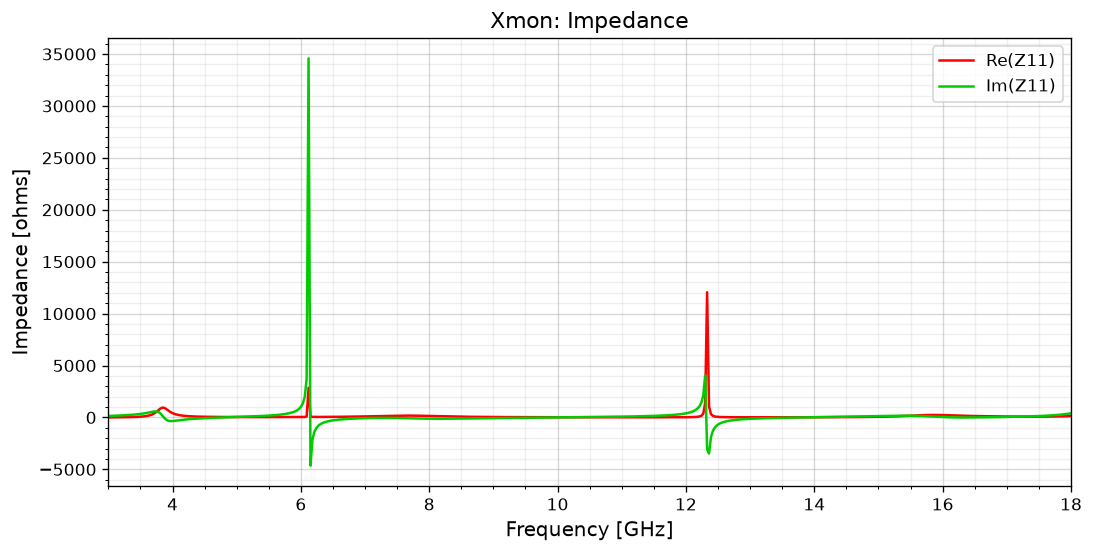

In [26]:
fig_z, ax_z = plot_hfss_curves(
    f_z, [re_z, im_z], labels=["Re(Z11)", "Im(Z11)"],
    colors=["red", "#00cc00"], title="Xmon: Impedance",
    ylabel="Impedance [ohms]",
)

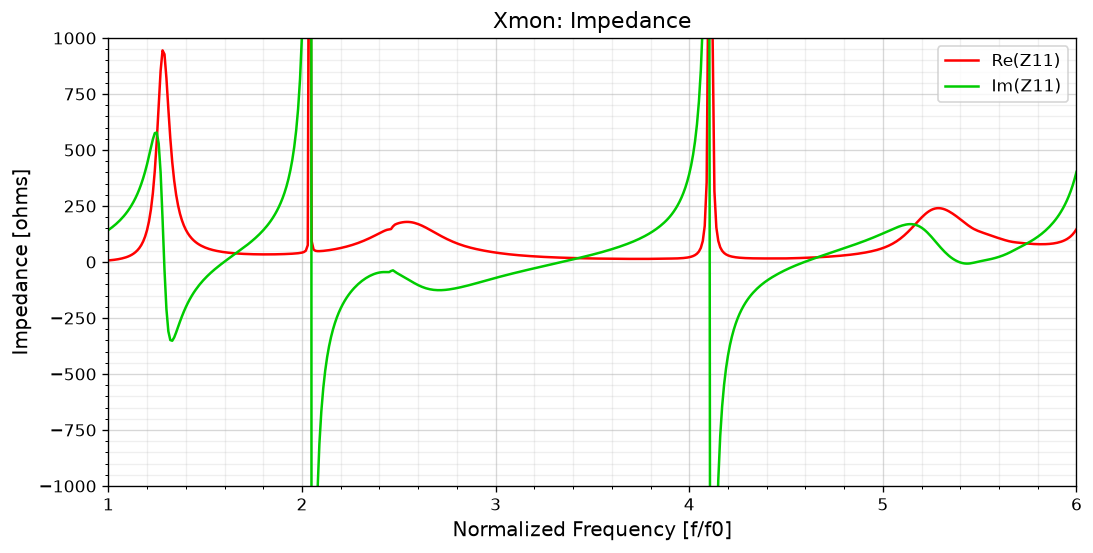

In [27]:
freq0 = 3
f_z_norm = f_z / freq0
fig_z, ax_z = plot_hfss_curves(
    f_z_norm, [re_z, im_z], labels=["Re(Z11)", "Im(Z11)"],
    colors=["red", "#00cc00"], title="Xmon: Impedance",
    ylabel="Impedance [ohms]", ylim=[-1000, 1000], xlabel="Normalized Frequency [f/f0]",
)

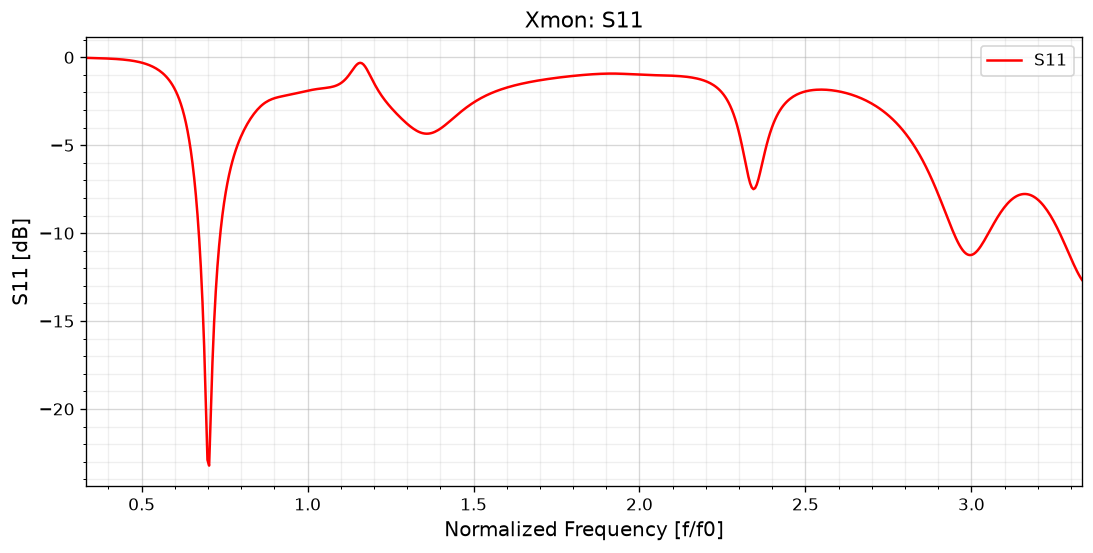

In [5]:
f_s_norm = f_s / freq0
fig_s, ax_s = plot_hfss_curves(
    f_s_norm, s11_db, labels=["S11"], colors=["red"],
    title="Xmon: S11", ylabel="S11 [dB]", xlabel="Normalized Frequency [f/f0]",
)

## Xmon02

In [ ]:
f_s, s11_db = np.loadtxt("data/Xmon02_S_Parameter_Plot.csv", delimiter=",", skiprows=1, unpack=True)
f_z, re_z, im_z = np.loadtxt("data/Xmon02_Z_Parameter_Plot.csv", delimiter=",", skiprows=1, unpack=True)

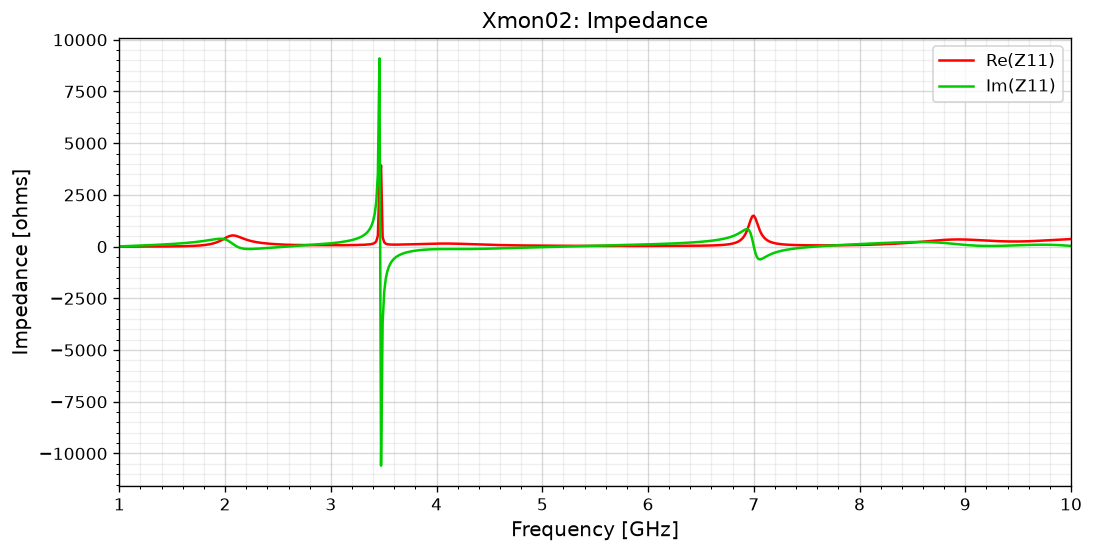

In [7]:
fig_z, ax_z = plot_hfss_curves(
    f_z, [re_z, im_z], labels=["Re(Z11)", "Im(Z11)"],
    colors=["red", "#00cc00"], title="Xmon02: Impedance",
    ylabel="Impedance [ohms]",
)

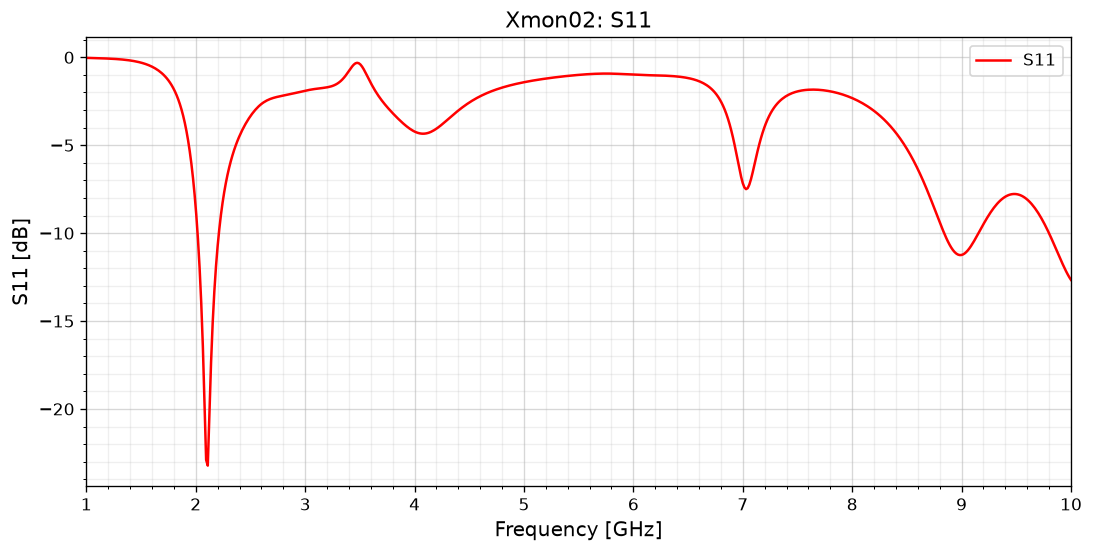

In [8]:
fig_s, ax_s = plot_hfss_curves(
    f_s, s11_db, labels=["S11"], colors=["red"],
    title="Xmon02: S11", ylabel="S11 [dB]",
)

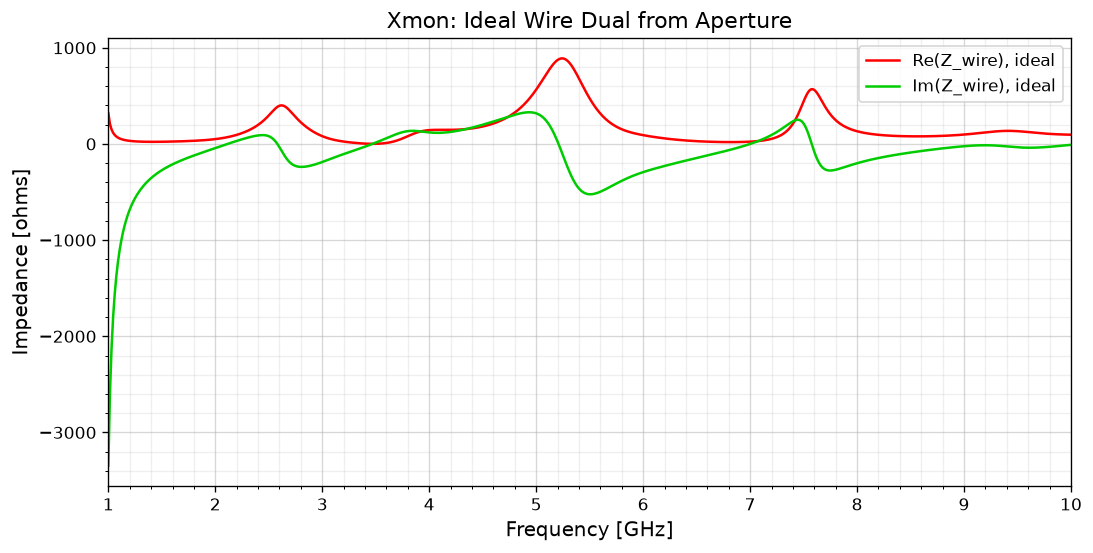

In [9]:
# Ideal wire dual from the aperture impedance loaded above (Xmon02).
# Rafferty et al., arXiv:2103.06803v2, Eq. (1): Za * Zw = eta0**2 / 4.
# https://arxiv.org/html/2103.06803v2#S2
# eta0 is the free-space impedance, NOT the 50-ohm port impedance.
# This assumes complementary ideal planar conductors and dual media:
# epsilon_r(wire) = mu_r(aperture), mu_r(wire) = epsilon_r(aperture).
eta0 = 376.730313668  # ohms
f_wire_ideal = f_z.copy()
z_aperture = re_z + 1j * im_z
if np.any(z_aperture == 0):
    raise ValueError("Zero aperture impedance gives a divergent ideal wire impedance.")
z_wire_ideal = eta0**2 / (4 * z_aperture)

fig_wire, ax_wire = plot_hfss_curves(
    f_wire_ideal, [z_wire_ideal.real, z_wire_ideal.imag],
    labels=["Re(Z_wire), ideal", "Im(Z_wire), ideal"],
    colors=["red", "#00cc00"], title="Xmon: Ideal Wire Dual from Aperture",
    ylabel="Impedance [ohms]",
)

## Babinet Theorem Validate

For ideal complementary wire and aperture antennas with corresponding feeds and electromagnetically dual media,

$$
Z_{\mathrm{aperture}}(f)\,Z_{\mathrm{wire}}(f)=\frac{\eta_0^2}{4},
\qquad
Z_{\mathrm{wire}}^{\mathrm{ideal}}(f)=\frac{\eta_0^2}{4Z_{\mathrm{aperture}}(f)},
$$

where $\eta_0=\sqrt{\mu_0/\varepsilon_0}\approx376.73\,\Omega$ is the free-space impedance, not the port reference impedance. The reciprocal is taken on the **complex impedance**, without complex conjugation.

Compare `Xmon02_wire_Z_Parameter_Plot.csv` with the ideal prediction calculated above from `Xmon02_Z_Parameter_Plot.csv`. Solid lines show the wire simulation; dashed lines show the ideal prediction. Both retain their original frequency samples, and the plots show only the common frequency range (no interpolation or extrapolation).

Source: [Rafferty et al., Spurious Antenna Modes of the Transmon Qubit, Eq. (1)](https://arxiv.org/html/2103.06803v2#S2).

The frequency axis is normalized as $f/f_0$, with `fre0 = 3.0` GHz. Impedance values are unchanged.

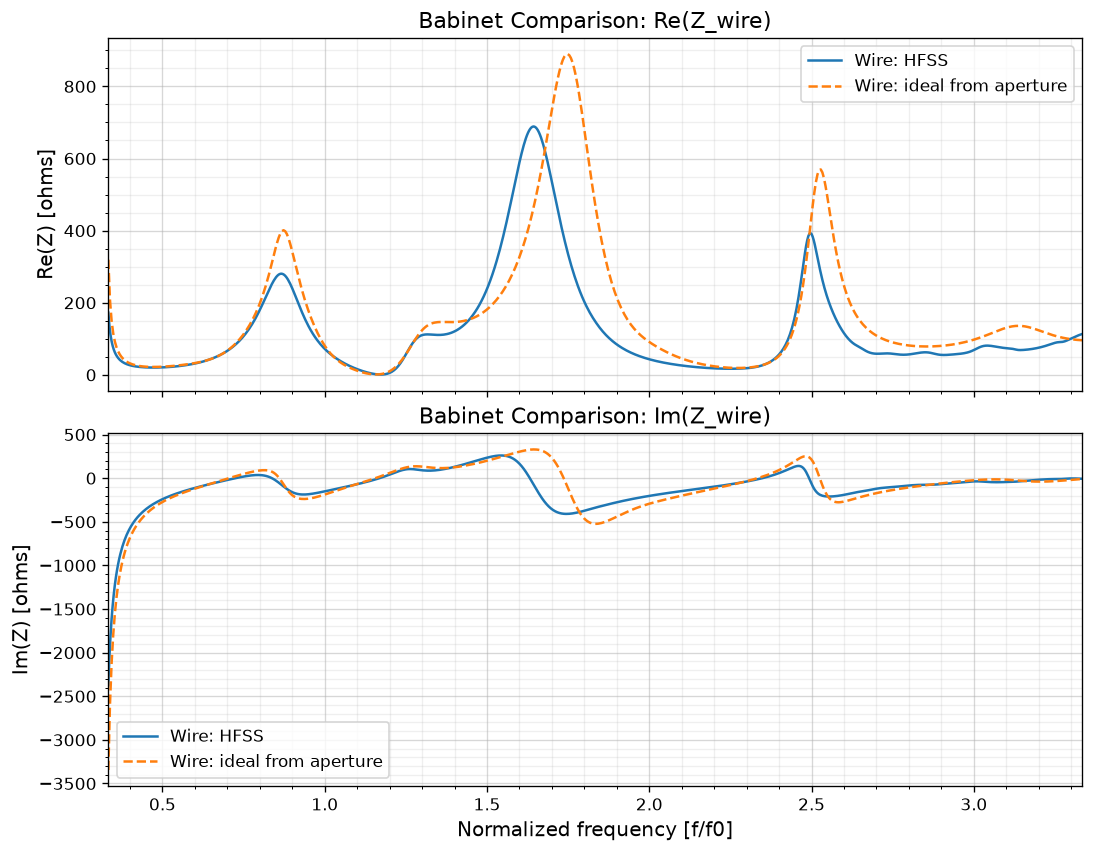

In [10]:
import matplotlib.pyplot as plt
from plotting_hfss import PLOT_CONFIG

f_wire_sim, re_wire_sim, im_wire_sim = np.loadtxt(
    "Xmon02_wire_Z_Parameter_Plot.csv", delimiter=",", skiprows=1, unpack=True,
)
z_wire_sim = re_wire_sim + 1j * im_wire_sim
fre0 = 3.0  # GHz; frequency normalization only
common_range = (max(f_wire_sim.min(), f_wire_ideal.min()),
                min(f_wire_sim.max(), f_wire_ideal.max()))
if common_range[0] >= common_range[1]:
    raise ValueError("The simulated and ideal data have no overlapping frequency range.")

sim_mask = (f_wire_sim >= common_range[0]) & (f_wire_sim <= common_range[1])
ideal_mask = (f_wire_ideal >= common_range[0]) & (f_wire_ideal <= common_range[1])

normalized_range = tuple(f / fre0 for f in common_range)

with plt.rc_context(PLOT_CONFIG):
    fig_validate, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                     layout="constrained")
for ax, simulated, ideal, part in zip(
    axes, [z_wire_sim.real, z_wire_sim.imag],
    [z_wire_ideal.real, z_wire_ideal.imag], ["Re", "Im"],
):
    plot_hfss_curves(
        f_wire_sim[sim_mask] / fre0, simulated[sim_mask], ax=ax, labels=["Wire: HFSS"], colors=["tab:blue"],
        title=f"Babinet Comparison: {part}(Z_wire)", ylabel=f"{part}(Z) [ohms]",
        xlim=normalized_range, xlabel="Normalized frequency [f/f0]", flag_show=False,
    )
    plot_hfss_curves(
        f_wire_ideal[ideal_mask] / fre0, ideal[ideal_mask], ax=ax, labels=["Wire: ideal from aperture"],
        colors=["tab:orange"], linestyles=["--"], ylabel=f"{part}(Z) [ohms]",
        xlim=normalized_range, xlabel="Normalized frequency [f/f0]", flag_show=False,
    )
axes[0].set_xlabel("")
plt.show()

## Junction Coupling and Antenna Noise Bandwidth

Following [Rafferty et al., Eqs. (3)-(6) and Fig. 4(d-f)](https://arxiv.org/html/2103.06803v2#S4), model the **junction**, not the entire low-frequency transmon, as $R_n\parallel C_j$, with $R_n=7\,\mathrm{k}\Omega$ and $C_j=9\,\mathrm{fF}$.

Assume all simulated linear dimensions are $s=3/0.024=125$ times the target dimensions. Under ideal PEC, nondispersive homogeneous-medium scaling, map the vacuum **aperture** data to $\epsilon_{\rm eff}=6$, $\mu_r=1$:

$$f_{\rm target}=\frac{s}{\sqrt{6}}f_{\rm sim},\qquad
Z_{\rm rad}(f_{\rm target})=\frac{Z_{\rm aperture,sim}(f_{\rm sim})}{\sqrt{6}}.$$

This is an effective-medium approximation, not a replacement for a finite-substrate simulation. The magnetic medium $\mu_r=6$ applies to the wire dual; it is not used for this aperture calculation. Interpret the exported input impedance as radiation impedance only when other losses and feed parasitics are negligible. The target junction parameters are fixed; they are not geometrically rescaled.

$$Z_j(f)=\frac{R_n}{1+j\omega R_nC_j}
=R_n\frac{1-j\omega\tau}{1+\omega^2\tau^2},\quad \tau=R_nC_j,\quad\omega=2\pi f.$$

$$\Gamma=\frac{Z_{\rm rad}-Z_j^*}{Z_{\rm rad}+Z_j},\qquad
e_c=1-|\Gamma|^2=\frac{4\operatorname{Re}Z_{\rm rad}\operatorname{Re}Z_j}{|Z_{\rm rad}+Z_j|^2},\qquad
\Delta f_N=\int e_c(f)\,df.$$

Panels (d,e) compare $Z_{\rm rad}$ with $Z_j^*$; panel (f) displays $10\log_{10}e_c$. Integration uses **linear** efficiency without peak normalization. The 50-150 GHz plot window follows the paper; finite-band integrals below are not automatically the isolated-mode or infinite-range bandwidth. The high-frequency RC model should not be interpreted as a physical sub-gap junction model.


In [11]:
# Use the aperture CSV explicitly, independent of earlier notebook variables.
f_sim_ghz, r_aperture, x_aperture = np.loadtxt(
    "Xmon02_Z_Parameter_Plot.csv", delimiter=",", skiprows=1, unpack=True,
)
size_scale = 3 / 0.024  # 125  # simulated length / target length
eps_eff = 6.0
rn = 7e3  # ohms
cj = 9e-15  # farads
f_target_ghz = f_sim_ghz * size_scale / np.sqrt(eps_eff)
z_rad = (r_aperture + 1j * x_aperture) / np.sqrt(eps_eff)
omega = 2 * np.pi * f_target_ghz * 1e9
z_j = rn / (1 + 1j * omega * rn * cj)
gamma_j = (z_rad - z_j.conj()) / (z_rad + z_j)
e_c = 1 - np.abs(gamma_j)**2

# Independent algebraic check; do not clip unphysical results.
np.testing.assert_allclose(e_c, 4 * z_rad.real * z_j.real / np.abs(z_rad + z_j)**2,
                           atol=1e-12, rtol=1e-10)
if np.any((e_c < 0) | (e_c > 1)):
    raise ValueError("Efficiency is outside [0, 1]; inspect impedance/passivity.")
with np.errstate(divide="ignore"):
    e_c_db = 10 * np.log10(e_c)
print(f"Frequency scale: {size_scale / np.sqrt(eps_eff):.6f}")
print(f"Target frequency range: {f_target_ghz[0]:.3f}-{f_target_ghz[-1]:.3f} GHz")
print(f"Target frequency step: {np.median(np.diff(f_target_ghz)):.3f} GHz")

Frequency scale: 51.031036
Target frequency range: 51.031-510.310 GHz
Target frequency step: 0.765 GHz


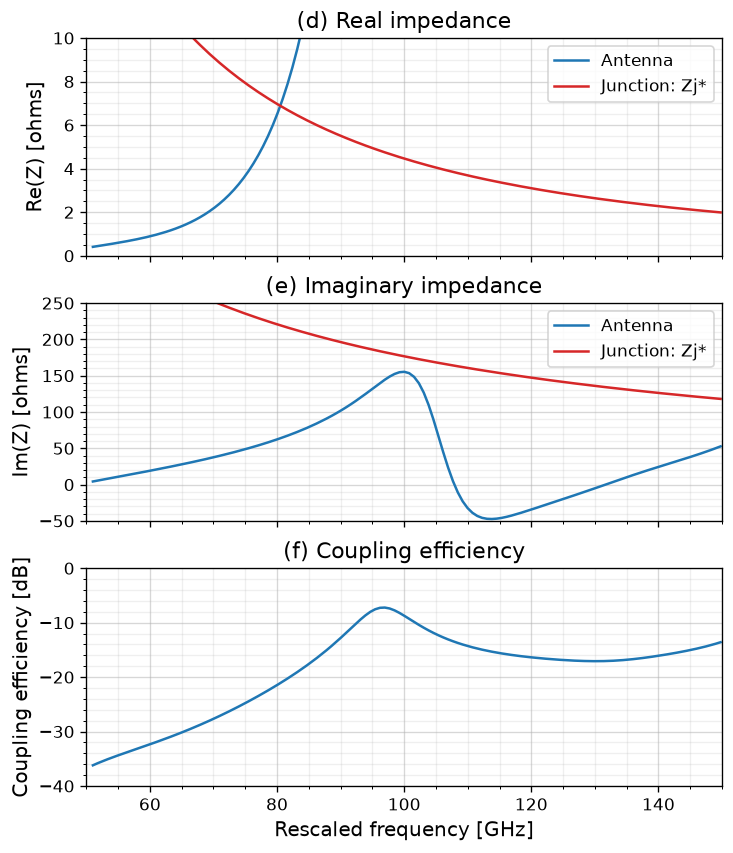

In [12]:
import matplotlib.pyplot as plt
from plotting_hfss import PLOT_CONFIG

plot_band_ghz = (50.0, 150.0)
view = (f_target_ghz >= plot_band_ghz[0]) & (f_target_ghz <= plot_band_ghz[1])
with plt.rc_context(PLOT_CONFIG):
    fig_coupling, axes_coupling = plt.subplots(
        3, 1, figsize=(6, 7), sharex=True, layout="constrained",
    )
for ax, curves, title, ylabel, limits in [
    (axes_coupling[0], [z_rad.real, z_j.conj().real],
     "(d) Real impedance", "Re(Z) [ohms]", (0, 10)),
    (axes_coupling[1], [z_rad.imag, z_j.conj().imag],
     "(e) Imaginary impedance", "Im(Z) [ohms]", (-50, 250)),
]:
    plot_hfss_curves(
        f_target_ghz[view], [v[view] for v in curves], ax=ax,
        labels=["Antenna", "Junction: Zj*"], colors=["tab:blue", "tab:red"],
        title=title, ylabel=ylabel, xlabel="", xlim=plot_band_ghz, ylim=limits,
        flag_show=False,
    )
plot_hfss_curves(
    f_target_ghz[view], e_c_db[view], ax=axes_coupling[2], colors=["tab:blue"],
    title="(f) Coupling efficiency", ylabel="Coupling efficiency [dB]",
    xlabel="Rescaled frequency [GHz]", xlim=plot_band_ghz, ylim=(-40, 0), flag_show=False,
)
plt.show()

In [24]:
from scipy.integrate import trapezoid

# Editable integration band; endpoints use linear interpolation, never extrapolation.
# Integrate only available samples; do not extrapolate down to 50 GHz.
band_ghz = (max(50.0, float(f_target_ghz[0])), 150.0)
if not f_target_ghz[0] <= band_ghz[0] < band_ghz[1] <= f_target_ghz[-1]:
    raise ValueError("Integration limits must lie within the simulated range.")
inside = (f_target_ghz > band_ghz[0]) & (f_target_ghz < band_ghz[1])
f_integral = np.r_[band_ghz[0], f_target_ghz[inside], band_ghz[1]]
e_integral = np.interp(f_integral, f_target_ghz, e_c)
noise_bandwidth_ghz = trapezoid(e_integral, f_integral)
noise_bandwidth_full_ghz = trapezoid(e_c, f_target_ghz)
peak_index = np.argmax(e_integral)
print(f"Band-limited noise bandwidth ({band_ghz[0]:g}-{band_ghz[1]:g} GHz): "
      f"{noise_bandwidth_ghz:.4f} GHz")
print(f"RC-model integral over all available data "
      f"({f_target_ghz[0]:.2f}-{f_target_ghz[-1]:.2f} GHz): "
      f"{noise_bandwidth_full_ghz:.4f} GHz")
print(f"Sampled peak in selected band: {f_integral[peak_index]:.3f} GHz; "
      f"efficiency = {e_integral[peak_index]:.4f} "
      f"({10*np.log10(e_integral[peak_index]):.2f} dB)")
print("The full-range RC-model integral includes multiple peaks; sub-gap values are formal model outputs.")
print("Refine the HFSS frequency sampling near coupling peaks before claiming a converged bandwidth.")

Band-limited noise bandwidth (51.031-150 GHz): 3.3635 GHz
RC-model integral over all available data (51.03-510.31 GHz): 10.4401 GHz
Sampled peak in selected band: 96.959 GHz; efficiency = 0.1894 (-7.23 dB)
The full-range RC-model integral includes multiple peaks; sub-gap values are formal model outputs.
Refine the HFSS frequency sampling near coupling peaks before claiming a converged bandwidth.
